# PRCP-1027 — Skin Disorder Prediction

**Domain:** Healthcare

## Project Objective

This single Jupyter Notebook completes the project requirements:

1. Prepare a complete data analysis report on the given skin-disorder dataset.
2. Build and compare multiple machine-learning classification models to predict the six classes of skin disease.
3. Provide practical suggestions for doctors on using the model as an early-support tool.

The notebook also includes:
- Data inspection and cleaning
- Missing-value treatment
- Exploratory Data Analysis
- Class-distribution analysis
- Age analysis
- Feature scaling
- Stratified train/test split
- Multiple classification algorithms
- Accuracy, precision, recall and F1-score
- Confusion matrices
- Model comparison report
- Feature-importance analysis
- Final production-model selection based on test performance
- Challenges and solutions
- Final conclusion


## Problem Statement

### Task 1 — Data Analysis
Prepare a complete data analysis report on the given data.

### Task 2 — Predictive Model
Create a predictive model using machine-learning techniques to predict the various classes of skin disease.

### Task 3 — Suggestions
Provide suggestions to doctors to support earlier identification of possible skin diseases.

### Model Comparison Report
Compare multiple machine-learning models and select a model for production based on the test-set performance.

### Challenges Report
Document the challenges faced in the data and explain the techniques used to handle them.

All tasks are implemented in this single Jupyter Notebook.


## Dataset Information

The dataset contains **366 patient records** and **34 input attributes** plus the target `class`.

According to the project description:
- 11 attributes are clinical.
- 22 attributes are histopathological.
- Age is a linear-valued attribute.
- Clinical and histopathological features generally use values from 0 to 3.
- `family_history` uses 0/1.
- The target contains six skin-disease classes.

The six classes represented by the class IDs are:

| Class | Disease |
|---:|---|
| 1 | Psoriasis |
| 2 | Seboreic dermatitis |
| 3 | Lichen planus |
| 4 | Pityriasis rosea |
| 5 | Cronic dermatitis |
| 6 | Pityriasis rubra pilaris |

The dataset file used in this notebook is the uploaded `dataset_35_dermatology (1).csv`.


# 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully")


Libraries imported successfully


# 2. Load the Dataset

The uploaded CSV file is loaded into a Pandas DataFrame.


In [2]:
import os

file_path = "dataset_35_dermatology (1).csv"

if not os.path.exists(file_path):
    # Useful when the notebook is opened from a different folder.
    csv_files = [
        f for f in os.listdir(".")
        if f.lower().endswith(".csv")
    ]

    matching_files = [
        f for f in csv_files
        if "dermatology" in f.lower()
    ]

    if len(matching_files) == 0:
        raise FileNotFoundError(
            "The dermatology CSV file was not found. "
            "Place 'dataset_35_dermatology (1).csv' in the same folder as this notebook."
        )

    file_path = matching_files[0]

df = pd.read_csv(file_path)

print("File loaded:", file_path)
print("Dataset shape:", df.shape)


File loaded: dataset_35_dermatology (1).csv
Dataset shape: (366, 35)


# 3. First Look at the Data

In [3]:
display(df.head())


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [4]:
display(df.tail())


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())


Rows: 366
Columns: 35

Column names:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_in_the_infiltrate', 'PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_of_the_granular_layer', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw-tooth_appearance_of_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate', 'band-like_infiltrate', 'Age', 'class']


# 4. Dataset Information

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

# 5. Missing Values

The original dataset represents some missing age values with the character `?`.

These values must be converted to missing numeric values before machine-learning models are trained.


In [7]:
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nQuestion-mark values:")
print("Age:", (df["Age"].astype(str).str.strip() == "?").sum())


Missing values before cleaning:


erythema                                    0
vacuolisation_and_damage_of_basal_layer     0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epidermis    0
spongiform_pustule                          0
munro_microabcess                           0
focal_hypergranulosis                       0
disappearance_of_the_granular_layer         0
spongiosis                                  0
parakeratosis                               0
dtype: int64


Question-mark values:
Age: 8


# 6. Data Cleaning

### Age
The `Age` column contains numeric values and some `?` entries.

The `?` entries are converted to `NaN`, then missing ages are filled using the median age of the available patients.

### Target
The `class` column is retained as the prediction target.


In [8]:
df_clean = df.copy()

df_clean["Age"] = pd.to_numeric(
    df_clean["Age"].replace("?", np.nan),
    errors="coerce"
)

age_median = df_clean["Age"].median()

df_clean["Age"] = df_clean["Age"].fillna(age_median)

print("Median age used for missing values:", age_median)
print("Remaining missing values:", df_clean.isnull().sum().sum())


Median age used for missing values: 35.0
Remaining missing values: 0


# 7. Duplicate Records

In [9]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

print("Dataset shape after cleaning:", df_clean.shape)


Duplicate rows: 0
No duplicate rows found.
Dataset shape after cleaning: (366, 35)


# 8. Data Summary

In [10]:
display(df_clean.describe().T)


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0


# 9. Target Class Distribution

The target contains six disease classes. Class distribution is checked before modelling because an imbalanced target can affect model evaluation.


In [11]:
class_counts = df_clean["class"].value_counts().sort_index()

class_names = {
    1: "Psoriasis",
    2: "Seboreic dermatitis",
    3: "Lichen planus",
    4: "Pityriasis rosea",
    5: "Cronic dermatitis",
    6: "Pityriasis rubra pilaris"
}

class_distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Disease": [class_names.get(i, f"Class {i}") for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(df_clean) * 100).round(2)
})

display(class_distribution)


,Class,Disease,Count,Percentage
0,1,Psoriasis,112,30.60
1,2,Seboreic dermatitis,61,16.67
2,3,Lichen planus,72,19.67
3,4,Pityriasis rosea,49,13.39
4,5,Cronic dermatitis,52,14.21
5,6,Pityriasis rubra pilaris,20,5.46


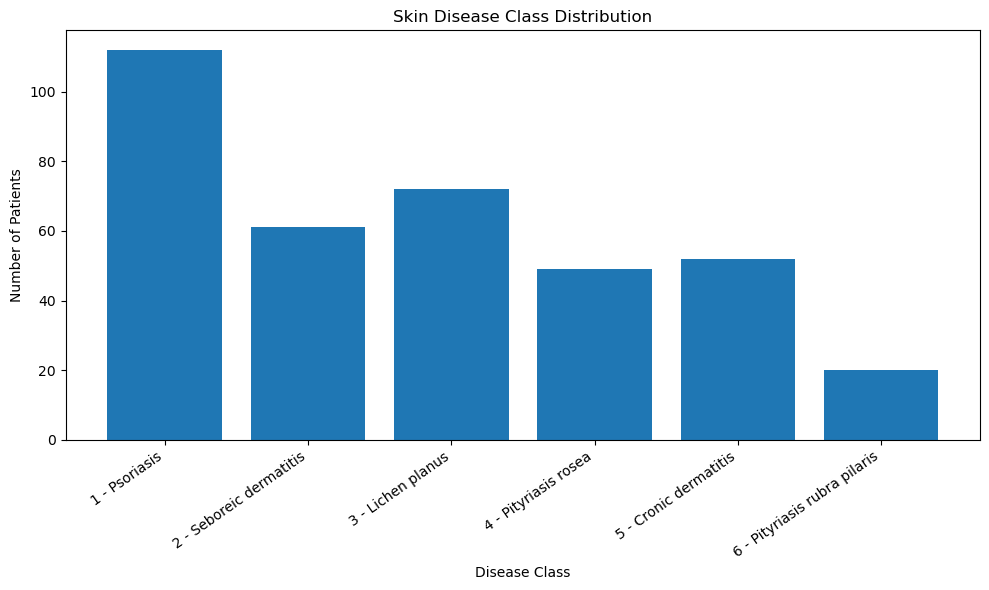

In [12]:
plt.figure(figsize=(10, 6))

labels = [
    f"{row['Class']} - {row['Disease']}"
    for _, row in class_distribution.iterrows()
]

plt.bar(labels, class_distribution["Count"])

plt.title("Skin Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Patients")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


# 10. Age Analysis

In [13]:
print("Age statistics:")
display(df_clean["Age"].describe())


Age statistics:


count    366.000000
mean      36.267760
std       15.156875
min        0.000000
25%       25.000000
50%       35.000000
75%       48.000000
max       75.000000
Name: Age, dtype: float64

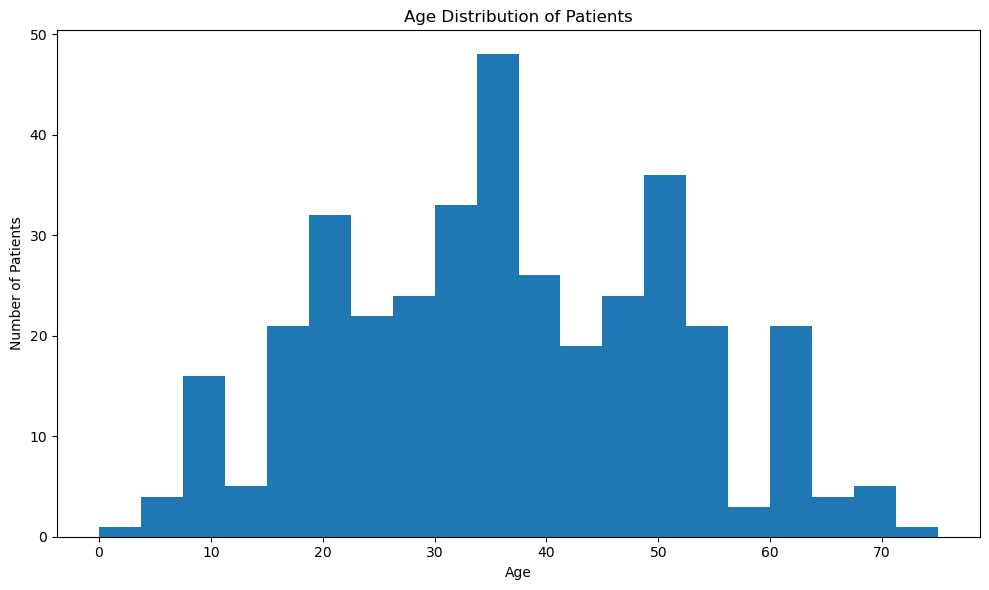

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(df_clean["Age"], bins=20)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


## Age by Disease Class

In [15]:
age_by_class = (
    df_clean
    .groupby("class")["Age"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

age_by_class["Disease"] = [
    class_names.get(i, f"Class {i}")
    for i in age_by_class.index
]

display(age_by_class)


,count,mean,median,min,max,Disease
class,,,,,,
1,112,39.34,38.5,0.0,75.0,Psoriasis
2,61,35.46,34.0,10.0,70.0,Seboreic dermatitis
3,72,39.89,40.0,16.0,65.0,Lichen planus
4,49,35.27,35.0,12.0,70.0,Pityriasis rosea
5,52,36.54,35.0,8.0,70.0,Cronic dermatitis
6,20,10.25,9.5,7.0,22.0,Pityriasis rubra pilaris


# 11. Clinical Feature Analysis

The first 11 attributes represent clinical information according to the project description.

The following plot shows the average clinical-feature values for each disease class.


In [16]:
clinical_features = [
    "erythema",
    "scaling",
    "definite_borders",
    "itching",
    "koebner_phenomenon",
    "polygonal_papules",
    "follicular_papules",
    "oral_mucosal_involvement",
    "knee_and_elbow_involvement",
    "scalp_involvement",
    "family_history"
]

clinical_means = df_clean.groupby("class")[clinical_features].mean()

display(clinical_means.round(2))


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history
class,,,,,,,,,,,
1,2.29,2.20,2.10,0.95,0.67,0.00,0.04,0.00,1.63,1.53,0.29
2,2.28,2.07,0.95,1.62,0.03,0.00,0.02,0.00,0.07,0.11,0.05
3,2.08,1.62,2.10,2.28,1.35,2.28,0.00,1.92,0.03,0.03,0.01
4,1.90,1.51,1.18,0.47,1.18,0.00,0.00,0.00,0.00,0.00,0.00
5,1.50,1.13,0.85,1.88,0.00,0.00,0.23,0.00,0.04,0.00,0.00
6,2.05,1.75,1.05,0.50,0.00,0.00,2.20,0.00,1.70,0.50,0.50


<Figure size 1500x700 with 0 Axes>

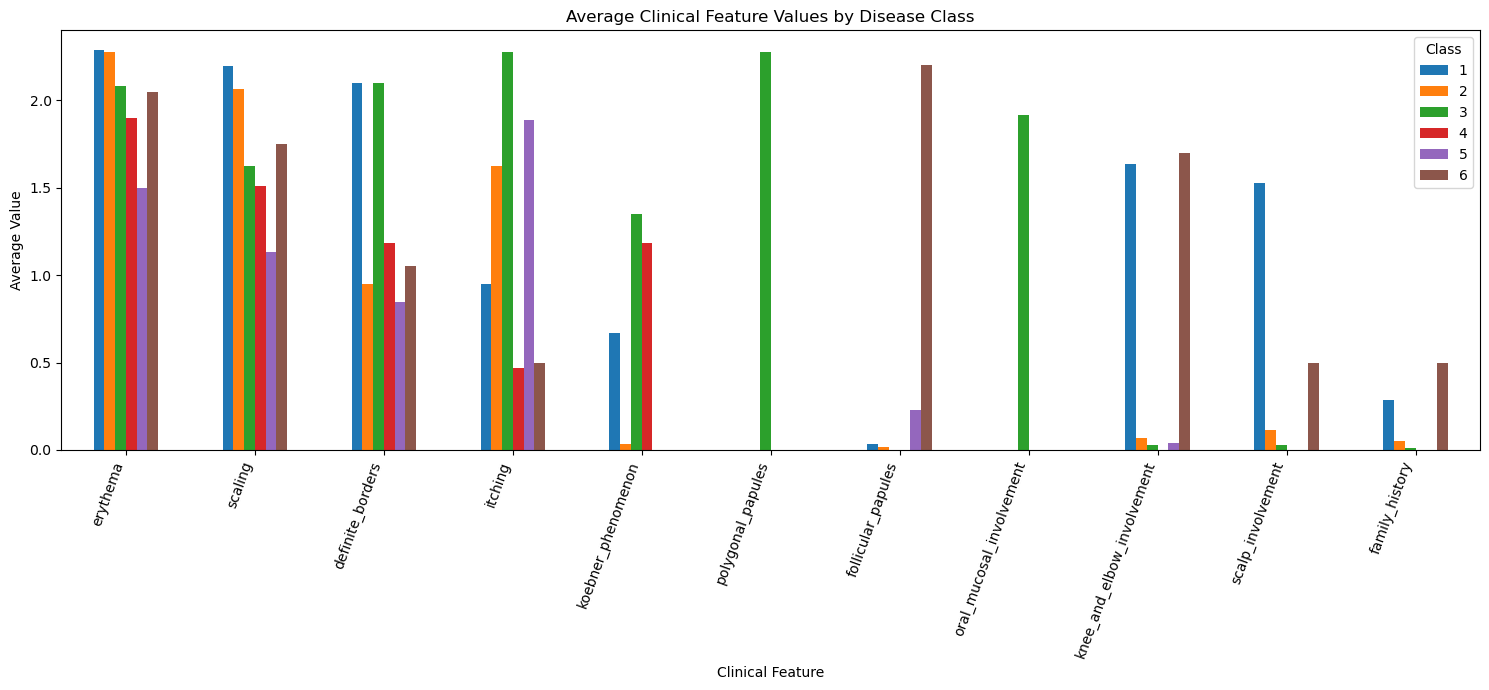

In [17]:
plt.figure(figsize=(15, 7))

clinical_means.T.plot(kind="bar", figsize=(15, 7))

plt.title("Average Clinical Feature Values by Disease Class")
plt.xlabel("Clinical Feature")
plt.ylabel("Average Value")
plt.xticks(rotation=70, ha="right")
plt.legend(title="Class")

plt.tight_layout()
plt.show()


# 12. Histopathological Feature Analysis

The project description identifies 22 histopathological attributes.

The average value of these features is compared across the six disease classes.


In [18]:
histopathological_features = [
    "melanin_incontinence",
    "eosinophils_in_the_infiltrate",
    "PNL_infiltrate",
    "fibrosis_of_the_papillary_dermis",
    "exocytosis",
    "acanthosis",
    "hyperkeratosis",
    "parakeratosis",
    "clubbing_of_the_rete_ridges",
    "elongation_of_the_rete_ridges",
    "thinning_of_the_suprapapillary_epidermis",
    "spongiform_pustule",
    "munro_microabcess",
    "focal_hypergranulosis",
    "disappearance_of_the_granular_layer",
    "vacuolisation_and_damage_of_basal_layer",
    "spongiosis",
    "saw-tooth_appearance_of_retes",
    "follicular_horn_plug",
    "perifollicular_parakeratosis",
    "inflammatory_monoluclear_inflitrate",
    "band-like_infiltrate"
]

hist_means = df_clean.groupby("class")[histopathological_features].mean()

display(hist_means.round(2))


,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,...,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate
class,,,,,,,,,,,,,,,,,,,,,
1,0.00,0.04,1.12,0.00,0.27,2.10,0.82,2.00,2.12,2.26,...,1.15,0.00,1.20,0.01,0.00,0.00,0.00,0.00,1.87,0.03
2,0.00,0.46,1.08,0.00,2.20,1.77,0.21,0.98,0.00,0.16,...,0.00,0.00,0.00,0.00,2.16,0.00,0.02,0.02,1.61,0.03
3,2.06,0.17,0.00,0.06,2.26,2.11,0.29,1.21,0.00,0.00,...,0.04,1.99,0.24,2.31,1.10,2.29,0.01,0.00,2.25,2.72
4,0.00,0.06,0.12,0.00,2.04,1.45,0.31,0.76,0.00,0.00,...,0.02,0.00,0.39,0.00,1.96,0.02,0.00,0.00,1.78,0.00
5,0.00,0.08,0.00,2.29,0.85,2.25,0.69,0.75,0.08,1.88,...,0.00,0.00,0.00,0.00,0.35,0.00,0.02,0.00,1.83,0.02
6,0.00,0.00,0.15,0.00,1.50,1.65,0.80,1.25,0.10,0.10,...,0.00,0.05,0.00,0.00,1.20,0.00,1.75,2.05,1.60,0.05


<Figure size 1600x800 with 0 Axes>

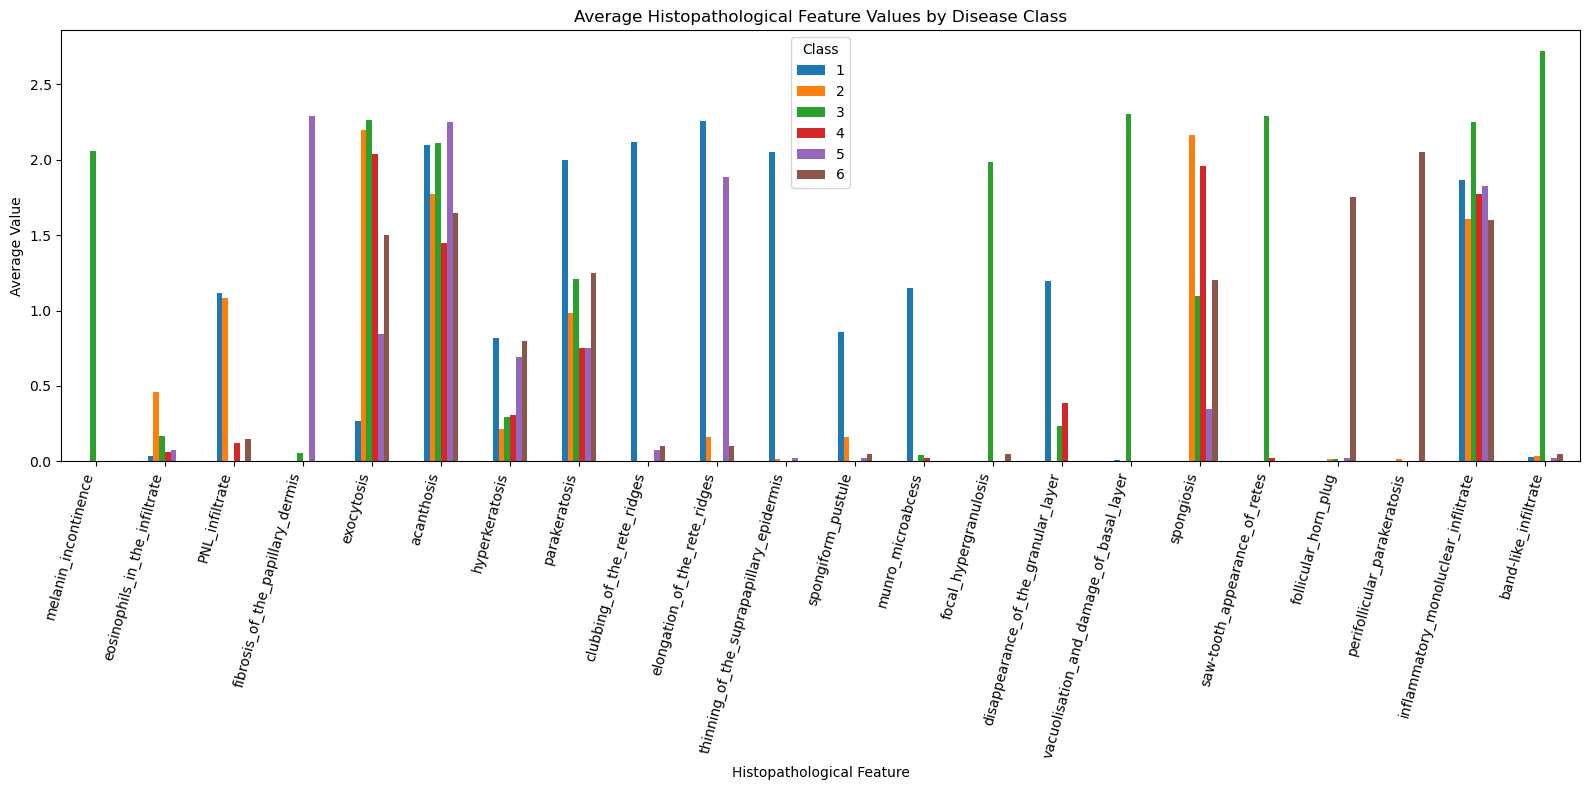

In [19]:
plt.figure(figsize=(16, 8))

hist_means.T.plot(kind="bar", figsize=(16, 8))

plt.title("Average Histopathological Feature Values by Disease Class")
plt.xlabel("Histopathological Feature")
plt.ylabel("Average Value")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Class")

plt.tight_layout()
plt.show()


# 13. Feature and Target Preparation

`class` is the target variable.

All other columns are input features.

The dataset contains 34 input attributes:
- 33 feature values described as clinical/histopathological/age information
- 1 age feature

No patient name or ID is used as a predictor.


In [20]:
X = df_clean.drop("class", axis=1)
y = df_clean["class"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])


Feature matrix shape: (366, 34)
Target shape: (366,)
Number of features: 34


# 14. Train-Test Split

A **stratified 80/20 split** is used.

Stratification keeps the relative distribution of the six disease classes approximately consistent between training and testing data.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index())


Training samples: 292
Testing samples : 74

Training class distribution:


class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64


Testing class distribution:


class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64

# 15. Machine-Learning Models

The following classification algorithms are compared:

1. Logistic Regression
2. K-Nearest Neighbors
3. Decision Tree
4. Random Forest
5. Support Vector Machine
6. Gradient Boosting

Standard scaling is used inside pipelines for algorithms that benefit from comparable feature scales.

The same train/test split is used for every model to make the comparison consistent.


In [22]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ])
}

print("Models prepared:", len(models))


Models prepared: 6


# 16. Train and Evaluate All Models

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score

For multi-class healthcare classification, macro-averaged precision, recall and F1-score are reported so that every disease class contributes equally to the metric.


In [23]:
results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Macro": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

for column in ["Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro"]:
    results_df[column] = results_df[column].round(4)

display(results_df.sort_values("F1_Macro", ascending=False).reset_index(drop=True))


  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                      

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Support Vector Machine,0.9730,0.9722,0.9722,0.9697
1,Logistic Regression,0.9595,0.9615,0.9611,0.9574
2,Random Forest,0.9595,0.9545,0.9556,0.9545
3,Gradient Boosting,0.9324,0.9062,0.9250,0.9125
4,K-Nearest Neighbors,0.9054,0.9071,0.9094,0.9034
5,Decision Tree,0.9324,0.9293,0.8778,0.8878


# 17. Model Comparison Report

The production candidate is selected using the **highest macro F1-score** on the held-out test set.

Macro F1 is used because the dataset contains six disease classes and the model should perform well across all classes rather than relying only on the largest class.


In [24]:
results_ranked = (
    results_df
    .sort_values(
        by=["F1_Macro", "Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(results_ranked)

best_model_name = results_ranked.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Selected production candidate:", best_model_name)
print("Selection metric: highest test-set macro F1-score")


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Support Vector Machine,0.9730,0.9722,0.9722,0.9697
1,Logistic Regression,0.9595,0.9615,0.9611,0.9574
2,Random Forest,0.9595,0.9545,0.9556,0.9545
3,Gradient Boosting,0.9324,0.9062,0.9250,0.9125
4,K-Nearest Neighbors,0.9054,0.9071,0.9094,0.9034
5,Decision Tree,0.9324,0.9293,0.8778,0.8878


Selected production candidate: Support Vector Machine
Selection metric: highest test-set macro F1-score


# 18. Model Performance Visualization

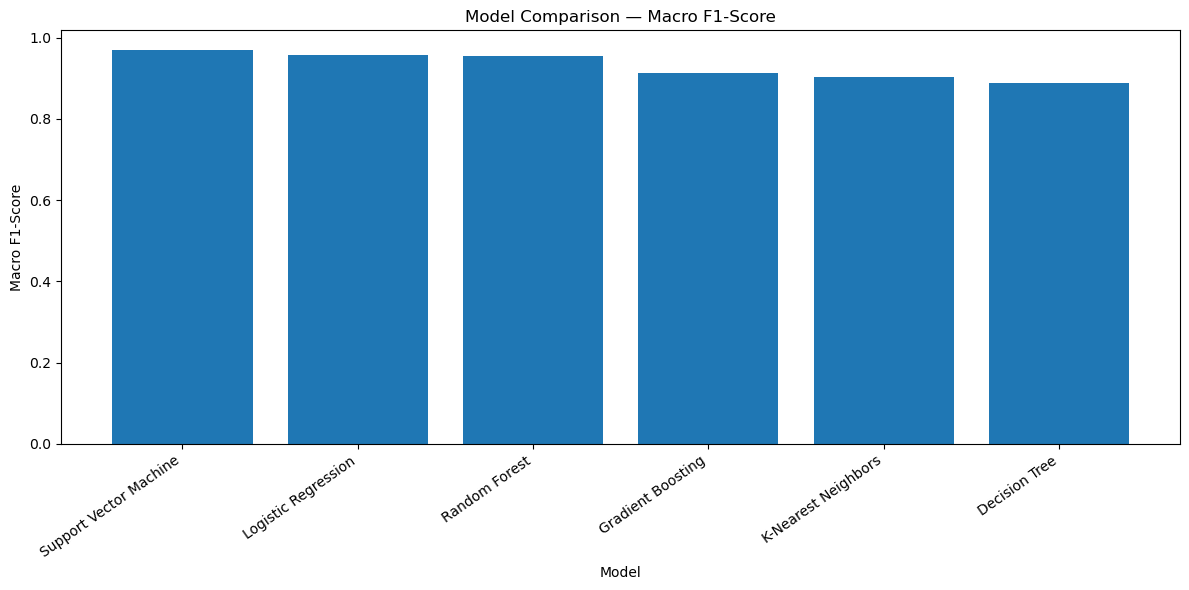

In [25]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_ranked["Model"],
    results_ranked["F1_Macro"]
)

plt.title("Model Comparison — Macro F1-Score")
plt.xlabel("Model")
plt.ylabel("Macro F1-Score")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


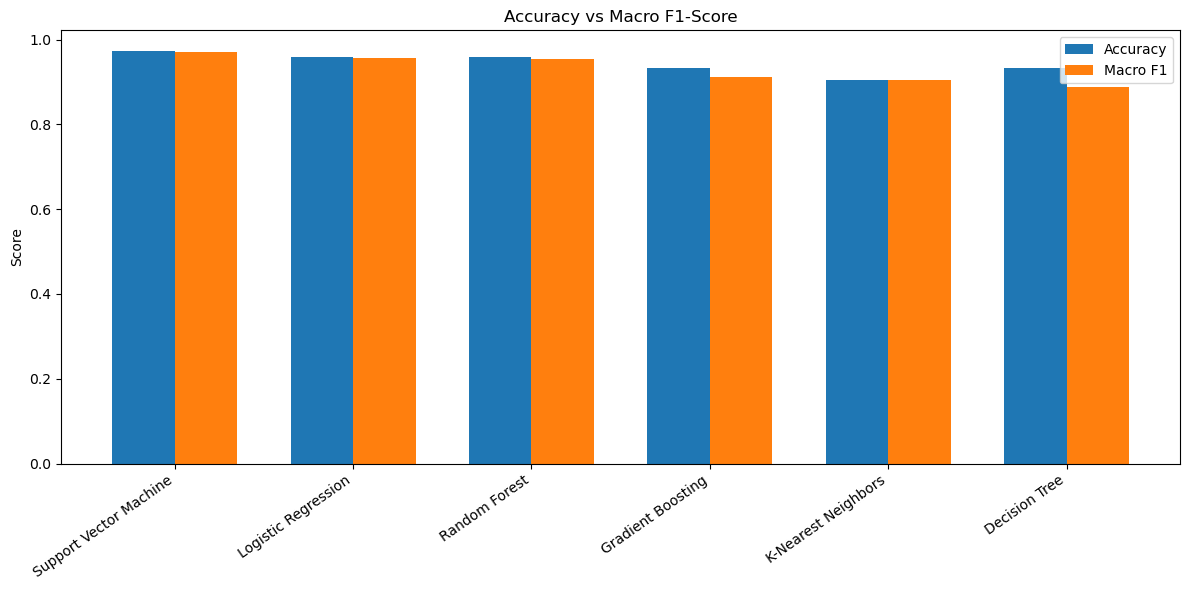

In [26]:
plt.figure(figsize=(12, 6))

x = np.arange(len(results_ranked))
width = 0.35

plt.bar(
    x - width/2,
    results_ranked["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    results_ranked["F1_Macro"],
    width,
    label="Macro F1"
)

plt.xticks(x, results_ranked["Model"], rotation=35, ha="right")
plt.ylabel("Score")
plt.title("Accuracy vs Macro F1-Score")
plt.legend()

plt.tight_layout()
plt.show()


# 19. Classification Report for the Selected Model

In [27]:
best_predictions = predictions[best_model_name]

target_labels = sorted(y.unique())
target_names = [
    class_names.get(label, f"Class {label}")
    for label in target_labels
]

print("Selected model:", best_model_name)
print()

print(
    classification_report(
        y_test,
        best_predictions,
        labels=target_labels,
        target_names=target_names,
        zero_division=0
    )
)


Selected model: Support Vector Machine

                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
     Seboreic dermatitis       1.00      0.83      0.91        12
           Lichen planus       1.00      1.00      1.00        15
        Pityriasis rosea       0.83      1.00      0.91        10
       Cronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.97        74
               macro avg       0.97      0.97      0.97        74
            weighted avg       0.98      0.97      0.97        74



# 20. Confusion Matrix

A confusion matrix shows which disease classes are correctly predicted and which classes are confused with each other.


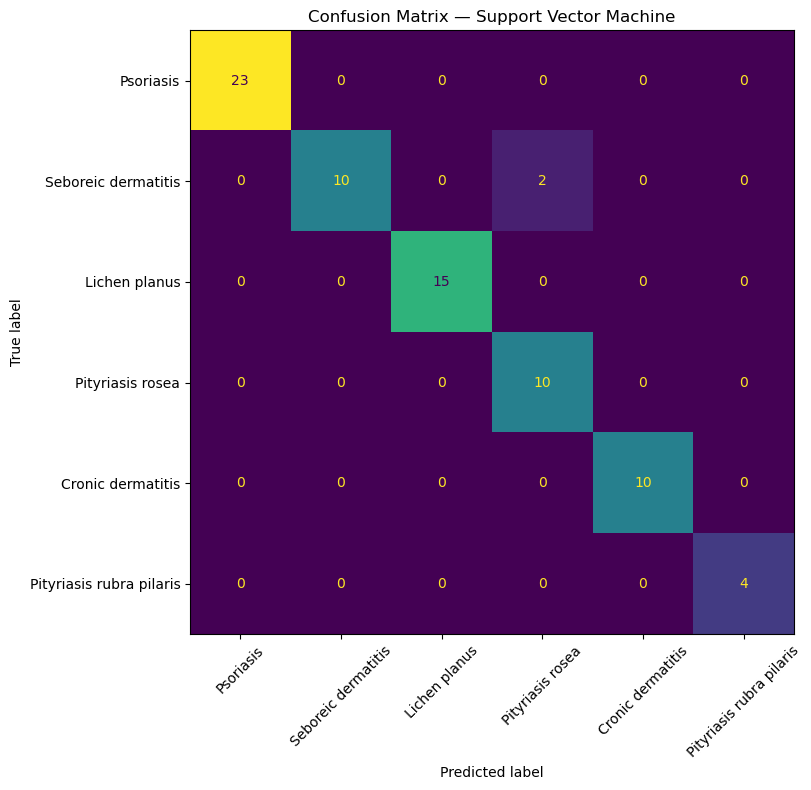

In [28]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=target_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


# 21. Class-Wise Performance

This section extracts precision, recall and F1-score for each disease class from the selected model.


In [29]:
report_dict = classification_report(
    y_test,
    best_predictions,
    labels=target_labels,
    target_names=target_names,
    output_dict=True,
    zero_division=0
)

class_report = pd.DataFrame(report_dict).T

class_report = class_report.loc[
    target_names,
    ["precision", "recall", "f1-score", "support"]
]

display(class_report.round(4))


,precision,recall,f1-score,support
Psoriasis,1.0000,1.0000,1.0000,23.0
Seboreic dermatitis,1.0000,0.8333,0.9091,12.0
Lichen planus,1.0000,1.0000,1.0000,15.0
Pityriasis rosea,0.8333,1.0000,0.9091,10.0
Cronic dermatitis,1.0000,1.0000,1.0000,10.0
Pityriasis rubra pilaris,1.0000,1.0000,1.0000,4.0


# 22. Feature Importance / Model Interpretation

For tree-based production candidates such as Random Forest or Gradient Boosting, feature importance can be extracted directly.

If the selected model is not tree-based, the notebook also provides a feature-importance view from a Random Forest as a general exploratory interpretation tool.

Feature importance indicates which variables contributed most to the Random Forest's predictions; it does not by itself establish medical causation.


In [30]:
# Fit an explanatory Random Forest
rf_explainer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_explainer.fit(X_train, y_train)

rf_model = rf_explainer.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(15))


,Feature,Importance
19,clubbing_of_the_rete_ridges,0.101277
14,fibrosis_of_the_papillary_dermis,0.078649
21,thinning_of_the_suprapapillary_epidermis,0.076322
4,koebner_phenomenon,0.062911
20,elongation_of_the_rete_ridges,0.058454
27,spongiosis,0.054888
13,PNL_infiltrate,0.040863
26,vacuolisation_and_damage_of_basal_layer,0.037876
32,band-like_infiltrate,0.036468
24,focal_hypergranulosis,0.036142


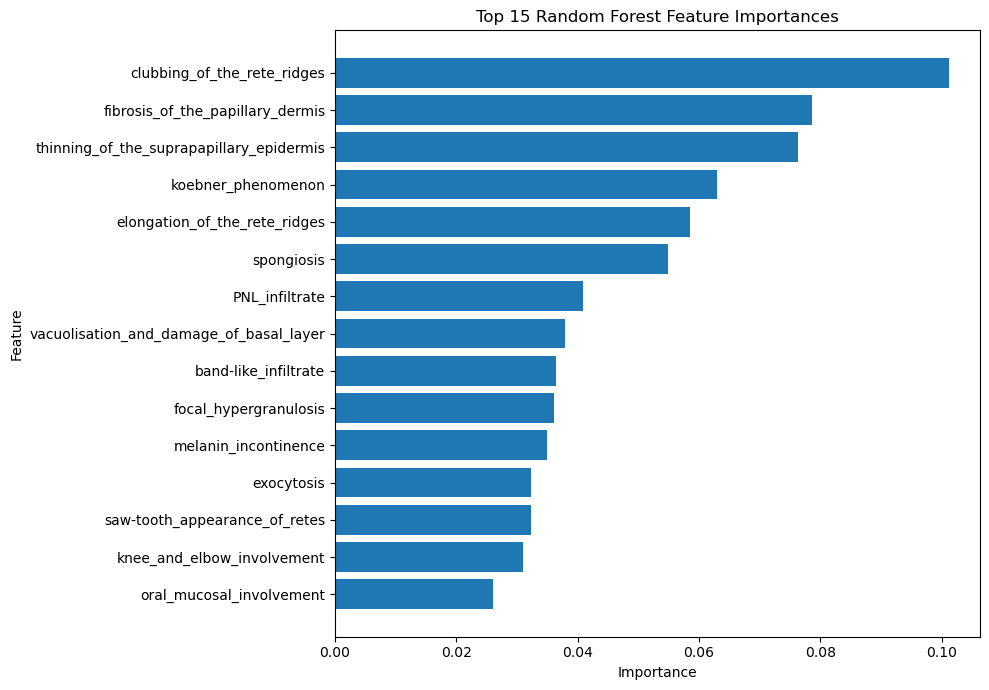

In [31]:
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# 23. Production Model Summary

The selected model below is the model with the highest macro F1-score on the held-out test set.

This is a data-science model selection result for this dataset. It is not a clinical validation or approval for diagnosis.


In [32]:
best_row = results_ranked.iloc[0]

production_summary = pd.DataFrame({
    "Item": [
        "Selected Model",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Value": [
        best_model_name,
        best_row["Accuracy"],
        best_row["Precision_Macro"],
        best_row["Recall_Macro"],
        best_row["F1_Macro"]
    ]
})

display(production_summary)


,Item,Value
0,Selected Model,Support Vector Machine
1,Accuracy,0.973
2,Macro Precision,0.9722
3,Macro Recall,0.9722
4,Macro F1,0.9697


# 24. Example Prediction on Test Patients

The trained selected model can predict the disease class for unseen feature records.

The examples below use actual held-out test records so that the output can be compared with their known test labels.


In [33]:
sample_count = min(10, len(X_test))

sample_X = X_test.iloc[:sample_count]
sample_y = y_test.iloc[:sample_count]
sample_pred = best_model.predict(sample_X)

prediction_examples = pd.DataFrame({
    "Actual_Class": sample_y.values,
    "Actual_Disease": [
        class_names.get(int(v), f"Class {v}")
        for v in sample_y.values
    ],
    "Predicted_Class": sample_pred,
    "Predicted_Disease": [
        class_names.get(int(v), f"Class {v}")
        for v in sample_pred
    ]
})

display(prediction_examples)


,Actual_Class,Actual_Disease,Predicted_Class,Predicted_Disease
0,2,Seboreic dermatitis,2,Seboreic dermatitis
1,3,Lichen planus,3,Lichen planus
2,4,Pityriasis rosea,4,Pityriasis rosea
3,1,Psoriasis,1,Psoriasis
4,4,Pityriasis rosea,4,Pityriasis rosea
5,3,Lichen planus,3,Lichen planus
6,4,Pityriasis rosea,4,Pityriasis rosea
7,1,Psoriasis,1,Psoriasis
8,2,Seboreic dermatitis,2,Seboreic dermatitis
9,3,Lichen planus,3,Lichen planus


# 25. Suggestions to Doctors

The machine-learning model can be used as an **early-support and decision-support tool**, not as a replacement for clinical examination, biopsy, pathology, or specialist judgement.

Suggested workflow:

1. Record the patient's clinical features consistently.
2. Record the relevant histopathological features when available.
3. Use the model to generate a preliminary class prediction.
4. Review the predicted class together with the patient's clinical history and examination.
5. Pay particular attention when the model prediction and clinical assessment disagree.
6. Consider specialist dermatology review and appropriate confirmatory testing when required.
7. Use model performance separately for each disease class rather than relying only on overall accuracy.
8. Monitor false positives and false negatives after deployment.
9. Retrain and revalidate the model when new representative patient data becomes available.
10. Before clinical deployment, perform independent external validation on appropriately collected clinical data.

### Important limitation

The dataset is relatively small and contains structured clinical/histopathological attributes. A strong test score on this dataset does not by itself demonstrate real-world clinical safety or diagnostic validity.


# 26. Challenges Faced and Techniques Used

### Challenge 1 — Missing Age Values
The dataset contains `?` in the Age column.

**Technique:** Convert `?` to missing values and impute the median age.

### Challenge 2 — Different Feature Scales
Age is measured on a larger numerical scale than most 0–3 clinical/histopathological features.

**Technique:** StandardScaler is used inside pipelines for scale-sensitive algorithms.

### Challenge 3 — Six-Class Classification
The task is not binary classification; six disease classes must be distinguished.

**Technique:** Use multi-class classification algorithms and macro-averaged evaluation metrics.

### Challenge 4 — Class Imbalance
The six classes do not contain the same number of patients.

**Technique:** Stratified train/test splitting and macro precision, recall and F1-score are used so that smaller classes are not hidden by overall accuracy.

### Challenge 5 — Small Dataset
The dataset contains only a few hundred patient records.

**Technique:** Use a fixed held-out test set, compare several models, and avoid unnecessarily complex deep-learning architectures for this tabular dataset.

### Challenge 6 — Potential Overfitting
Tree-based models can fit small tabular datasets very closely.

**Technique:** Compare several algorithms on the same unseen test set and use a relatively controlled Random Forest configuration.

### Challenge 7 — Clinical Interpretation
A machine-learning prediction should not automatically be treated as a medical diagnosis.

**Technique:** Present predictions as decision support and recommend clinical validation and specialist review.


# 27. Final Project Results

This notebook has completed:

- Complete dataset inspection
- Data cleaning
- Missing-value treatment
- Duplicate checking
- Descriptive statistics
- Class distribution analysis
- Age analysis
- Clinical feature analysis
- Histopathological feature analysis
- Six machine-learning classification models
- Accuracy comparison
- Precision comparison
- Recall comparison
- Macro F1 comparison
- Confusion matrix
- Class-wise performance
- Feature-importance analysis
- Production-model selection
- Example predictions
- Doctor-oriented suggestions
- Challenges and solutions


# 28. Conclusion

The dermatology dataset was analyzed and prepared for multi-class machine learning.

Multiple classification algorithms were trained and evaluated using a common stratified train/test split. The model with the highest macro F1-score on the held-out test data was selected as the production candidate for this project.

The analysis also identifies important predictive features and provides a framework for using the model as an early-support tool.

Because this is a healthcare classification problem, model performance on this dataset should not be interpreted as proof of clinical diagnostic safety. External validation, appropriate clinical evaluation and specialist oversight would be required before real-world clinical use.


In [34]:
print("=" * 70)
print("PRCP-1027 SKIN DISORDER PROJECT — FINAL SUMMARY")
print("=" * 70)

print("Dataset shape after cleaning:", df_clean.shape)
print("Number of input features:", X.shape[1])
print("Number of disease classes:", y.nunique())

print("\nSelected production candidate:", best_model_name)
print("Accuracy:", round(float(best_row["Accuracy"]), 4))
print("Macro Precision:", round(float(best_row["Precision_Macro"]), 4))
print("Macro Recall:", round(float(best_row["Recall_Macro"]), 4))
print("Macro F1:", round(float(best_row["F1_Macro"]), 4))

print("\nDisease classes:")
for class_id, disease in class_names.items():
    print(f"{class_id}: {disease}")

print("=" * 70)


PRCP-1027 SKIN DISORDER PROJECT — FINAL SUMMARY
Dataset shape after cleaning: (366, 35)
Number of input features: 34
Number of disease classes: 6

Selected production candidate: Support Vector Machine
Accuracy: 0.973
Macro Precision: 0.9722
Macro Recall: 0.9722
Macro F1: 0.9697

Disease classes:
1: Psoriasis
2: Seboreic dermatitis
3: Lichen planus
4: Pityriasis rosea
5: Cronic dermatitis
6: Pityriasis rubra pilaris
